<a href="https://colab.research.google.com/github/f2023-694-pixel/SmartCart_Analytics/blob/main/Copy_of_SmartCart_Analytics_Midterm_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SmartCart Analytics
### A Big Data Approach to Grocery Purchasing Behaviour Using PySpark

**Midterm Project – Google Colab Notebook**



## 1. Install and import libraries

In [ ]:
!pip install pyspark

from pyspark.sql import SparkSession
from pyspark.sql.functions import *
from pyspark.sql.types import *
from pyspark.sql.window import Window
import matplotlib.pyplot as plt
import pandas as pd

## 2. Create Spark session

In [ ]:
spark = SparkSession.builder.appName("SmartCart Analytics").getOrCreate()
print("Spark Version:", spark.version)

Spark Version: 4.0.5


## 3. Upload and load datasets

In [ ]:
orders = spark.read.csv("/content/orders.csv", header=True, inferSchema=True)
order_products = spark.read.csv("/content/order_products__train.csv", header=True, inferSchema=True)
products = spark.read.csv("/content/products.csv", header=True, inferSchema=True)
aisles = spark.read.csv("/content/aisles.csv", header=True, inferSchema=True)
departments = spark.read.csv("/content/departments.csv", header=True, inferSchema=True)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 4. Explore datasets

In [ ]:
for name, df in [
    ("ORDERS", orders), ("ORDER PRODUCTS", order_products),
    ("PRODUCTS", products), ("AISLES", aisles), ("DEPARTMENTS", departments)
]:
    print(name)
    df.show(5)
    df.printSchema()
    print("Total rows:", df.count())

ORDERS
+--------+-------+--------+------------+---------+-----------------+----------------------+
|order_id|user_id|eval_set|order_number|order_dow|order_hour_of_day|days_since_prior_order|
+--------+-------+--------+------------+---------+-----------------+----------------------+
| 2539329|      1|   prior|           1|        2|                8|                  NULL|
| 2398795|      1|   prior|           2|        3|                7|                  15.0|
|  473747|      1|   prior|           3|        3|               12|                  21.0|
| 2254736|      1|   prior|           4|        4|                7|                  29.0|
|  431534|      1|   prior|           5|        4|               15|                  28.0|
+--------+-------+--------+------------+---------+-----------------+----------------------+
only showing top 5 rows
root
 |-- order_id: integer (nullable = true)
 |-- user_id: integer (nullable = true)
 |-- eval_set: string (nullable = true)
 |-- order_numb

## 5. Check missing values

In [ ]:
for name, df in [
    ("Orders", orders), ("Order Products", order_products),
    ("Products", products), ("Aisles", aisles), ("Departments", departments)
]:
    print(name)
    df.select([count(when(col(c).isNull(), c)).alias(c) for c in df.columns]).show()

Orders
+--------+-------+--------+------------+---------+-----------------+----------------------+
|order_id|user_id|eval_set|order_number|order_dow|order_hour_of_day|days_since_prior_order|
+--------+-------+--------+------------+---------+-----------------+----------------------+
|       0|      0|       0|           0|        0|                0|                206209|
+--------+-------+--------+------------+---------+-----------------+----------------------+

Order Products
+--------+----------+-----------------+---------+
|order_id|product_id|add_to_cart_order|reordered|
+--------+----------+-----------------+---------+
|       0|         0|                0|        0|
+--------+----------+-----------------+---------+

Products
+----------+------------+--------+-------------+
|product_id|product_name|aisle_id|department_id|
+----------+------------+--------+-------------+
|         0|           0|       0|            0|
+----------+------------+--------+-------------+

Aisles
+---

## 6. Data cleaning

In [ ]:
orders = orders.dropDuplicates(["order_id"])
order_products = order_products.dropDuplicates(["order_id", "product_id"])
products = products.dropDuplicates(["product_id"])
aisles = aisles.dropDuplicates(["aisle_id"])
departments = departments.dropDuplicates(["department_id"])

orders = orders.filter(col("order_id").isNotNull())
order_products = order_products.dropna(subset=["order_id", "product_id"])
products = products.dropna(subset=["product_id", "product_name"])
order_products = order_products.withColumn("reordered", col("reordered").cast("integer"))

print("Data cleaning completed")

Data cleaning completed


## 7. Data preprocessing

In [ ]:
orders = orders.withColumn("order_hour_of_day", col("order_hour_of_day").cast("integer"))
orders = orders.withColumn("order_dow", col("order_dow").cast("integer"))
orders = orders.withColumn("order_number", col("order_number").cast("integer"))
order_products = order_products.withColumn("add_to_cart_order", col("add_to_cart_order").cast("integer"))
print("Preprocessing completed")

Preprocessing completed


## 8. Integrate datasets using joins

In [ ]:
train_orders = orders.filter(col("eval_set") == "train")
data = train_orders.join(order_products, "order_id", "inner")
data = data.join(products, "product_id", "inner")
data = data.join(aisles, "aisle_id", "left")
data = data.join(departments, "department_id", "left")

data.show(10)
print("Total integrated rows:", data.count())
data.printSchema()

+-------------+--------+----------+--------+-------+--------+------------+---------+-----------------+----------------------+-----------------+---------+--------------------+--------------------+------------+
|department_id|aisle_id|product_id|order_id|user_id|eval_set|order_number|order_dow|order_hour_of_day|days_since_prior_order|add_to_cart_order|reordered|        product_name|               aisle|  department|
+-------------+--------+----------+--------+-------+--------+------------+---------+-----------------+----------------------+-----------------+---------+--------------------+--------------------+------------+
|            4|      24|     13176|    1342| 156818|   train|          32|        3|                8|                  30.0|                1|        1|Bag of Organic Ba...|        fresh fruits|     produce|
|            4|      32|     30827|    1342| 156818|   train|          32|        3|                8|                  30.0|                2|        1|  Seedless 

## 9. Feature engineering

In [ ]:
data = data.withColumn(
    "day_name",
    when(col("order_dow") == 0, "Sunday")
    .when(col("order_dow") == 1, "Monday")
    .when(col("order_dow") == 2, "Tuesday")
    .when(col("order_dow") == 3, "Wednesday")
    .when(col("order_dow") == 4, "Thursday")
    .when(col("order_dow") == 5, "Friday")
    .otherwise("Saturday")
)
data = data.withColumn(
    "time_period",
    when(col("order_hour_of_day") < 12, "Morning")
    .when(col("order_hour_of_day") < 17, "Afternoon")
    .otherwise("Evening")
)
data = data.withColumn(
    "reorder_status",
    when(col("reordered") == 1, "Reordered").otherwise("First Time")
)
data.show(5)

+-------------+--------+----------+--------+-------+--------+------------+---------+-----------------+----------------------+-----------------+---------+--------------------+----------+--------------------+-------------+------------+--------+-----------+--------------+
|department_id|aisle_id|product_id|order_id|user_id|eval_set|order_number|order_dow|order_hour_of_day|days_since_prior_order|add_to_cart_order|reordered|        product_name|product_id|        product_name|department_id|  department|day_name|time_period|reorder_status|
+-------------+--------+----------+--------+-------+--------+------------+---------+-----------------+----------------------+-----------------+---------+--------------------+----------+--------------------+-------------+------------+--------+-----------+--------------+
|            4|      83|     49683|       1| 112108|   train|           4|        4|               10|                   9.0|                4|        0|      Cucumber Kirby|        45|   Eu

## 10. Product and department analysis

In [ ]:
from pyspark.sql.functions import desc, col

# Automatically resolve duplicate column names in the active DataFrame context
unique_cols = {}
for i, name in enumerate(data.columns):
    if name not in unique_cols:
        unique_cols[name] = i

# Select only the first occurrence of each column name
clean_data = data.toDF(*[f"_col_{i}" for i in range(len(data.columns))])
clean_data = clean_data.select([col(f"_col_{idx}").alias(name) for name, idx in unique_cols.items()])

# Top 10 Products
print("Top 10 Products")
top_products = clean_data.groupBy("product_name").count()
top_products = top_products.orderBy(desc("count"))
top_products.show(10)

# Purchases by Department
print("Purchases by Department")
department_analysis = clean_data.groupBy("department").count()
department_analysis = department_analysis.orderBy(desc("count"))
department_analysis.show()

# Top 10 Aisles
print("Top 10 Aisles")
if "aisle" in clean_data.columns:
    clean_data.groupBy("aisle").count().orderBy(desc("count")).show(10)
else:
    print("Column 'aisle' not found in DataFrame schemas. Please run Section 8 again.")

Top 10 Products
+--------------------+-----+
|        product_name|count|
+--------------------+-----+
|              Banana|18726|
|Bag of Organic Ba...|15480|
|Organic Strawberries|10894|
|Organic Baby Spinach| 9784|
|         Large Lemon| 8135|
|     Organic Avocado| 7409|
|Organic Hass Avocado| 7293|
|        Strawberries| 6494|
|               Limes| 6033|
| Organic Raspberries| 5546|
+--------------------+-----+
only showing top 10 rows
Purchases by Department
+---------------+------+
|     department| count|
+---------------+------+
|        produce|409087|
|     dairy eggs|217051|
|         snacks|118862|
|      beverages|114046|
|         frozen|100426|
|         pantry| 81242|
|         bakery| 48394|
|   canned goods| 46799|
|           deli| 44291|
|dry goods pasta| 38713|
|      household| 35986|
|   meat seafood| 30307|
|      breakfast| 29500|
|  personal care| 21570|
|         babies| 14941|
|  international| 11902|
|        missing|  8251|
|        alcohol|  5598|
|   

## 11. Customer purchasing behaviour

In [ ]:
customer_analysis = orders.groupBy("user_id").agg(
    count("order_id").alias("total_orders"),
    avg("days_since_prior_order").alias("average_days_between_orders"),
    max("order_number").alias("last_order_number")
)

customer_analysis = customer_analysis.withColumn(
    "customer_segment",
    when(col("total_orders") >= 20, "Frequent")
    .when(col("total_orders") >= 10, "Regular")
    .otherwise("Occasional")
)
customer_analysis.show(10)
customer_analysis.groupBy("customer_segment").count().show()

+-------+------------+---------------------------+-----------------+----------------+
|user_id|total_orders|average_days_between_orders|last_order_number|customer_segment|
+-------+------------+---------------------------+-----------------+----------------+
|    148|           8|          9.857142857142858|                8|      Occasional|
|    463|           8|                       19.0|                8|      Occasional|
|    471|           7|         10.833333333333334|                7|      Occasional|
|    496|          83|         3.4146341463414633|               83|        Frequent|
|    833|          12|         21.181818181818183|               12|         Regular|
|   1088|          16|         15.866666666666667|               16|         Regular|
|   1238|          30|         12.551724137931034|               30|        Frequent|
|   1342|           7|          8.666666666666666|                7|      Occasional|
|   1580|          10|         20.555555555555557|    

## 12. Time-based purchasing analysis

In [ ]:
from pyspark.sql.functions import col, count, when

# Safely verify and re-apply feature engineering if data was overwritten by the raw join in Section 8
analysis_data = data
if "day_name" not in analysis_data.columns:
    analysis_data = analysis_data.withColumn(
        "day_name",
        when(col("order_dow") == 0, "Sunday")
        .when(col("order_dow") == 1, "Monday")
        .when(col("order_dow") == 2, "Tuesday")
        .when(col("order_dow") == 3, "Wednesday")
        .when(col("order_dow") == 4, "Thursday")
        .when(col("order_dow") == 5, "Friday")
        .otherwise("Saturday")
    )

if "time_period" not in analysis_data.columns:
    analysis_data = analysis_data.withColumn(
        "time_period",
        when(col("order_hour_of_day") < 12, "Morning")
        .when(col("order_hour_of_day") < 17, "Afternoon")
        .otherwise("Evening")
    )

day_analysis = analysis_data.groupBy("day_name").agg(count("*").alias("total_purchases"))
print("Purchases by Day")
day_analysis.show()

hour_analysis = analysis_data.groupBy("order_hour_of_day").agg(
    count("*").alias("total_purchases")
).orderBy("order_hour_of_day")
print("Purchases by Hour")
hour_analysis.show()

print("Purchases by Time Period")
analysis_data.groupBy("time_period").count().show()

Purchases by Day
+---------+---------------+
| day_name|total_purchases|
+---------+---------------+
|Wednesday|         154381|
|  Tuesday|         160562|
|   Friday|         176910|
| Thursday|         155481|
| Saturday|         207279|
|   Monday|         205978|
|   Sunday|         324026|
+---------+---------------+

Purchases by Hour
+-----------------+---------------+
|order_hour_of_day|total_purchases|
+-----------------+---------------+
|                0|           9083|
|                1|           5626|
|                2|           3226|
|                3|           2438|
|                4|           2431|
|                5|           3847|
|                6|          11847|
|                7|          36302|
|                8|          67386|
|                9|          93856|
|               10|         110479|
|               11|         114119|
|               12|         111752|
|               13|         114762|
|               14|         119370|
|       

## 13. Reorder analysis

In [ ]:
from pyspark.sql.functions import col, avg, desc, when

# Dynamically check and re-apply feature engineering if data was overwritten by the raw join
analysis_data = data
if "reorder_status" not in analysis_data.columns:
    analysis_data = analysis_data.withColumn(
        "reorder_status",
        when(col("reordered") == 1, "Reordered").otherwise("First Time")
    )

reorder_analysis = analysis_data.groupBy("reorder_status").count()
reorder_analysis.show()

print("Reorder percentage")
analysis_data.agg((avg("reordered") * 100).alias("reorder_percentage")).show()

print("Most Reordered Products")
analysis_data.filter(col("reordered") == 1).groupBy("product_name").count().orderBy(desc("count")).show(10)

+--------------+------+
|reorder_status| count|
+--------------+------+
|    First Time|555793|
|     Reordered|828824|
+--------------+------+

Reorder percentage
+------------------+
|reorder_percentage|
+------------------+
|59.859441275096295|
+------------------+

Most Reordered Products
+--------------------+-----+
|        product_name|count|
+--------------------+-----+
|              Banana|16557|
|Bag of Organic Ba...|13362|
|Organic Strawberries| 8603|
|Organic Baby Spinach| 8055|
|     Organic Avocado| 6226|
|Organic Hass Avocado| 6042|
|         Large Lemon| 5923|
|        Strawberries| 4786|
| Organic Raspberries| 4279|
|               Limes| 4234|
+--------------------+-----+
only showing top 10 rows


## 14. PySpark RDD operations

In [ ]:
rdd = data.select("department").rdd.map(lambda row: row[0])
clean_rdd = rdd.filter(lambda x: x is not None)

print("MAP")
print(clean_rdd.map(lambda x: (x, 1)).take(10))

print("FILTER")
print(clean_rdd.filter(lambda x: x != "").take(10))

print("FLATMAP")
print(clean_rdd.flatMap(lambda x: x.split()).take(10))

print("REDUCE BY KEY")
print(clean_rdd.map(lambda x: (x, 1)).reduceByKey(lambda a, b: a + b).collect())

print("COMBINE BY KEY")
print(clean_rdd.map(lambda x: (x, 1)).combineByKey(
    lambda value: value,
    lambda total, value: total + value,
    lambda total1, total2: total1 + total2
).collect())

MAP
[('produce', 1), ('produce', 1), ('produce', 1), ('produce', 1), ('household', 1), ('produce', 1), ('meat seafood', 1), ('frozen', 1), ('bakery', 1), ('dairy eggs', 1)]
FILTER
['produce', 'produce', 'produce', 'produce', 'household', 'produce', 'meat seafood', 'frozen', 'bakery', 'dairy eggs']
FLATMAP
['produce', 'produce', 'produce', 'produce', 'household', 'produce', 'meat', 'seafood', 'frozen', 'bakery']
REDUCE BY KEY
[('produce', 409087), ('meat seafood', 30307), ('frozen', 100426), ('bakery', 48394), ('dairy eggs', 217051), ('deli', 44291), ('pantry', 81242), ('beverages', 114046), ('alcohol', 5598), ('dry goods pasta', 38713), ('other', 1795), ('canned goods', 46799), ('personal care', 21570), ('international', 11902), ('household', 35986), ('breakfast', 29500), ('snacks', 118862), ('missing', 8251), ('bulk', 1359), ('babies', 14941), ('pets', 4497)]
COMBINE BY KEY
[('produce', 409087), ('meat seafood', 30307), ('frozen', 100426), ('bakery', 48394), ('dairy eggs', 217051), ('

## 15. Ranking products

In [ ]:
window = Window.orderBy(desc("count"))
product_ranking = top_products.withColumn("product_rank", dense_rank().over(window))
product_ranking.show(10)

+--------------------+-----+------------+
|        product_name|count|product_rank|
+--------------------+-----+------------+
|              Banana|18726|           1|
|Bag of Organic Ba...|15480|           2|
|Organic Strawberries|10894|           3|
|Organic Baby Spinach| 9784|           4|
|         Large Lemon| 8135|           5|
|     Organic Avocado| 7409|           6|
|Organic Hass Avocado| 7293|           7|
|        Strawberries| 6494|           8|
|               Limes| 6033|           9|
| Organic Raspberries| 5546|          10|
+--------------------+-----+------------+
only showing top 10 rows


## 16. Spark SQL analysis

In [ ]:
data.createOrReplaceTempView("smartcart")

result = spark.sql("""
SELECT department,
       COUNT(*) AS total_purchases,
       SUM(reordered) AS total_reorders
FROM smartcart
GROUP BY department
ORDER BY total_purchases DESC
""")
result.show()

+---------------+---------------+--------------+
|     department|total_purchases|total_reorders|
+---------------+---------------+--------------+
|        produce|         409087|        271886|
|     dairy eggs|         217051|        146502|
|         snacks|         118862|         69102|
|      beverages|         114046|         75060|
|         frozen|         100426|         56168|
|         pantry|          81242|         29498|
|         bakery|          48394|         30692|
|   canned goods|          46799|         22782|
|           deli|          44291|         27367|
|dry goods pasta|          38713|         18885|
|      household|          35986|         15372|
|   meat seafood|          30307|         17907|
|      breakfast|          29500|         16864|
|  personal care|          21570|          7271|
|         babies|          14941|          8084|
|  international|          11902|          4522|
|        missing|           8251|          3148|
|        alcohol|   

## 17. Calculate project KPIs

In [ ]:
print("TOTAL ORDERS:", orders.count())
print("TOTAL CUSTOMERS:", orders.select("user_id").distinct().count())
print("TOTAL PRODUCTS:", products.count())
print("TOTAL PURCHASE RECORDS:", order_products.count())

print("AVERAGE PRODUCTS PER ORDER")
order_products.groupBy("order_id").count().agg(
    avg("count").alias("average_products")
).show()

print("AVERAGE ORDERS PER CUSTOMER")
customer_analysis.agg(
    avg("total_orders").alias("average_orders_per_customer")
).show()

TOTAL ORDERS: 3421083
TOTAL CUSTOMERS: 206209
TOTAL PRODUCTS: 49688
TOTAL PURCHASE RECORDS: 1384617
AVERAGE PRODUCTS PER ORDER
+------------------+
|  average_products|
+------------------+
|10.552759338155157|
+------------------+

AVERAGE ORDERS PER CUSTOMER
+---------------------------+
|average_orders_per_customer|
+---------------------------+
|         16.590367054784224|
+---------------------------+



## 18. Visualize top products

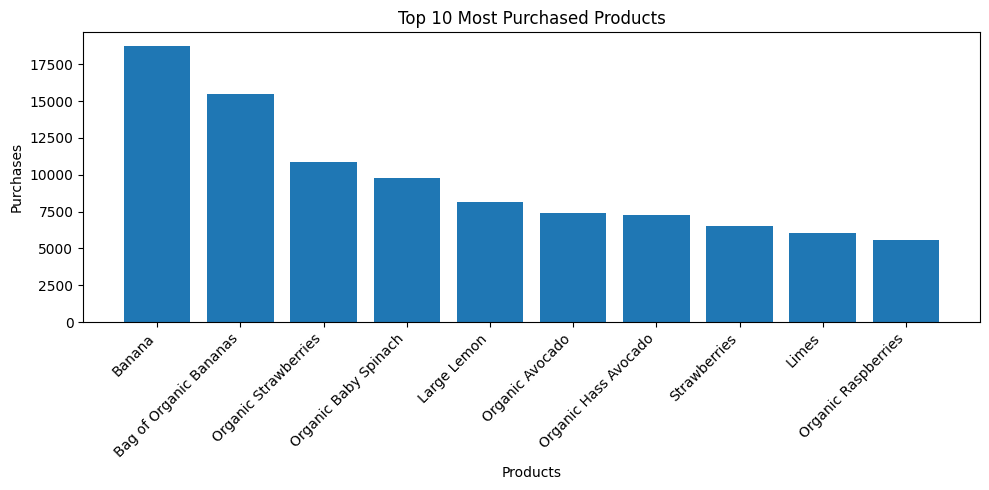

In [ ]:
top_products_pd = top_products.limit(10).toPandas()
plt.figure(figsize=(10, 5))
plt.bar(top_products_pd["product_name"], top_products_pd["count"])
plt.xticks(rotation=45, ha="right")
plt.title("Top 10 Most Purchased Products")
plt.xlabel("Products")
plt.ylabel("Purchases")
plt.tight_layout()
plt.show()

## 18. Visualize department purchases

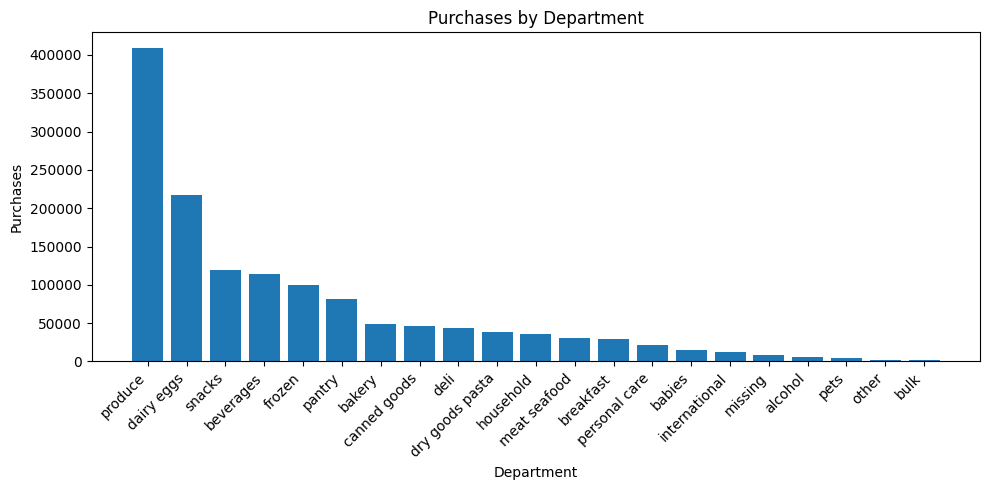

In [ ]:
department_pd = department_analysis.toPandas()
plt.figure(figsize=(10, 5))
plt.bar(department_pd["department"], department_pd["count"])
plt.xticks(rotation=45, ha="right")
plt.title("Purchases by Department")
plt.xlabel("Department")
plt.ylabel("Purchases")
plt.tight_layout()
plt.show()

## 18. Visualize purchases by hour

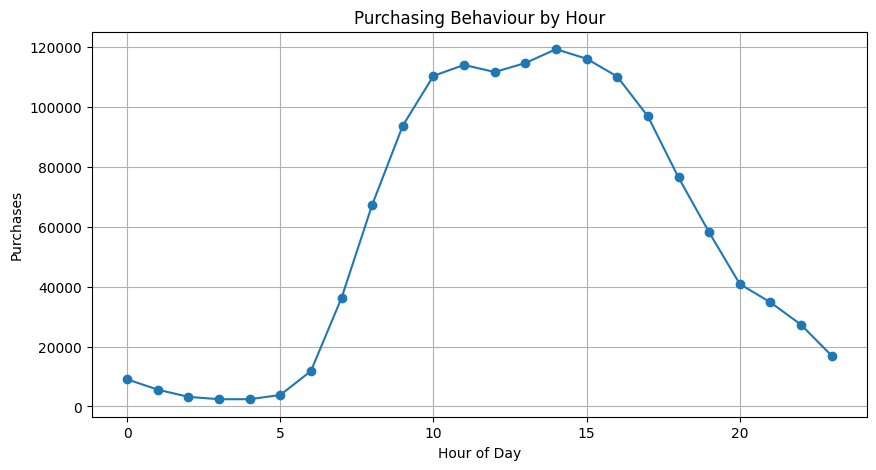

In [ ]:
hour_pd = hour_analysis.toPandas()
plt.figure(figsize=(10, 5))
plt.plot(hour_pd["order_hour_of_day"], hour_pd["total_purchases"], marker="o")
plt.title("Purchasing Behaviour by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Purchases")
plt.grid()
plt.show()

## 19. Save final results

In [ ]:
top_products.write.mode("overwrite").option("header", True).csv("top_products_results")
department_analysis.write.mode("overwrite").option("header", True).csv("department_results")
customer_analysis.write.mode("overwrite").option("header", True).csv("customer_analysis_results")
data.write.mode("overwrite").parquet("smartcart_final_dataset")

print("SmartCart Analytics Project Completed Successfully!")

SmartCart Analytics Project Completed Successfully!
